# ugali catalog input: FITS vs HATS validation

This notebook compares the **old** ugali catalog input (one FITS file per nside=32 healpix pixel)
with the **new** input (HATS parquet catalog, per-process LRU partition cache, parallel scan driver)
on the DES Y6 Gold catalog. It shows that

1. the catalog rows delivered are identical,
2. the likelihood scans are bit-identical between the two inputs (in the same Python environment),
3. what the cache does for neighbouring pixels, and
4. how long the scans take (single pixel, and a block of 8 neighbouring pixels, serial and parallel).

**Environment drift note.** This notebook runs in a numpy 2.5 / Python 3.14 environment, whereas the production
reference scans (`scan-v0`) were made with numpy 1.26. In this environment *both* the FITS and HATS paths differ from the
production reference by the same amount (typically ~1e-5 in log-likelihood, up to ~0.05 in flat-likelihood pixels). That is
a numerical-environment effect, not a HATS effect: HATS vs FITS is bit-identical here, and HATS run in the numpy 1.26 environment
reproduces production bit-for-bit.

The heavy cells need local data and are skipped (with a message) when it is missing, so the notebook runs through quickly elsewhere.

## 1. Setup and data availability

In [1]:
import os, sys, time, subprocess, shutil, csv, importlib.util, re
from pathlib import Path
os.environ.setdefault('OMP_NUM_THREADS', '1')
import numpy as np
import matplotlib.pyplot as plt

DES_DIR   = Path('/astro/users/chinyi/des_ugali')
REF_DIR   = DES_DIR / 'scan-v0'                      # production reference scans
PIXFILE   = DES_DIR / 'pixels.txt'
FITS_CAT  = str(DES_DIR / 'healpix' / 'y6_gold_2_2_%05i.fits')
HATS_PATH = Path('/astro/store/shire/hats/catalogs/des/des_y6_gold/des_y6_gold')

try:
    import ugali
    REPO = Path(ugali.__file__).resolve().parents[1]
except Exception:
    REPO = Path.cwd().parent
HIO = REPO / 'artifacts' / 'hats_io'
CFG_FITS, CFG_HATS = HIO / 'run_fits' / 'config.yaml', HIO / 'run_hats' / 'config.yaml'
RUNS = Path(os.environ.get('UGALI_NB_RUNS', HIO / 'notebook_runs'))

needed = [REF_DIR, PIXFILE, FITS_CAT % 10068, HATS_PATH / 'partition_info.csv', CFG_FITS, CFG_HATS]
HAVE_DATA = all(Path(p).exists() for p in needed)
for p in needed:
    print('%-5s %s' % ('ok' if Path(p).exists() else 'MISSING', p))
print('HAVE_DATA =', HAVE_DATA)

ok    /astro/users/chinyi/des_ugali/scan-v0
ok    /astro/users/chinyi/des_ugali/pixels.txt
ok    /astro/users/chinyi/des_ugali/healpix/y6_gold_2_2_10068.fits
ok    /astro/store/shire/hats/catalogs/des/des_y6_gold/des_y6_gold/partition_info.csv
ok    /astro/store/shire/pferguso/software/ugali_hats/artifacts/hats_io/run_fits/config.yaml
ok    /astro/store/shire/pferguso/software/ugali_hats/artifacts/hats_io/run_hats/config.yaml
HAVE_DATA = True


In [2]:
if HAVE_DATA:
    import healpy as hp, fitsio, yaml, platform
    import hats, pyarrow
    import ugali
    from ugali.observation import hats_catalog
    from ugali.observation.hats_catalog import HatsCatalogReader, get_reader
    from ugali.analysis.scan_parallel import run_scan, sort_nested
    import ugali.utils.config
    RUNS.mkdir(parents=True, exist_ok=True)
    print('python', platform.python_version(), '| numpy', np.__version__, '| healpy', hp.__version__,
          '| hats', hats.__version__, '| pyarrow', pyarrow.__version__)
    print('ugali', ugali.__file__)
    print('scratch dir:', RUNS)

    def make_run(name, kind):
        "Fresh run directory containing a config.yaml (relative output dirs land inside it)."
        d = RUNS / name
        if d.exists(): shutil.rmtree(d)
        d.mkdir(parents=True)
        shutil.copy(CFG_FITS if kind == 'fits' else CFG_HATS, d / 'config.yaml')
        return d

    def load_compare_fits():
        spec = importlib.util.spec_from_file_location('des_scan_tests', REPO / 'tests' / 'test_des_scan.py')
        m = importlib.util.module_from_spec(spec); spec.loader.exec_module(m)
        return m.compare_fits
    compare_fits = load_compare_fits()

    SCAN_COLS = [('HDU1', 'PIXEL'), ('HDU1', 'LOG_LIKELIHOOD'), ('HDU1', 'RICHNESS'),
                 ('HDU1', 'FRACTION_OBSERVABLE'), ('HDU2', 'DISTANCE_MODULUS')]
    def max_abs_diff(fa, fb):
        "max|a-b| per column of two scan files."
        out = {}
        A, B = fitsio.FITS(fa), fitsio.FITS(fb)
        for hdu, col in SCAN_COLS:
            i = int(hdu[-1])
            a = A[i].read()[col].astype(float); b = B[i].read()[col].astype(float)
            out[col] = float(np.nanmax(np.abs(a - b)))
        return out
else:
    print('data not available - skipping')

python 3.14.10 | numpy 2.5.4 | healpy 1.20.1 | hats 0.11.1 | pyarrow 26.0.1
ugali /astro/store/shire/pferguso/software/ugali_hats/ugali/__init__.py
scratch dir: /astro/store/shire/pferguso/software/ugali_hats/artifacts/hats_io/notebook_runs/final


## 2. Catalog-level equivalence

For three nside=32 catalog pixels, read the rows with the HATS reader (`load_pixels`, which applies the config selection
`FLAGS_GOLD == 0 & 0 <= EXT_XGB <= 2` per partition) and from the old FITS file with the same selection applied afterwards.
The rows are sorted by `COADD_OBJECT_ID` and every column compared.

In [3]:
if HAVE_DATA:
    cfg = ugali.utils.config.Config(str(CFG_HATS))
    sel_str = cfg['catalog']['selection']
    reader = HatsCatalogReader(str(HATS_PATH), columns=hats_catalog.default_columns(cfg),
                               selection=sel_str, max_tiles=8)
    reader.lon_field, reader.lat_field = 'RA', 'DEC'

    class _D:
        def __init__(self, d): self.data = d

    rows, cold_warm = [], []
    for pix in [10068, 10195, 10196]:
        keys = reader.partitions_for_pixels([pix], 32)
        t0 = time.time(); h = reader.load_pixels([pix], 32); t_cold = time.time() - t0
        t0 = time.time(); reader.load_pixels([pix], 32);     t_warm = time.time() - t0
        t0 = time.time(); f = fitsio.read(str(FITS_CAT % pix)); t_fits = time.time() - t0
        f = f[eval(sel_str, {'np': np}, {'self': _D(f)})]
        h = h[np.argsort(h['COADD_OBJECT_ID'])]; f = f[np.argsort(f['COADD_OBJECT_ID'])]
        same_ids = np.array_equal(h['COADD_OBJECT_ID'], f['COADD_OBJECT_ID'])
        maxd = max(float(np.max(np.abs(h[c].astype(float) - f[c].astype(float)))) if same_ids else np.nan
                   for c in h.dtype.names)
        rows.append((pix, str(keys), len(h), len(f), same_ids, maxd, t_cold, t_warm, t_fits))

    print('%-6s %-14s %9s %9s %9s %10s | %10s %10s %10s' % (
        'pixel', 'partition', 'HATS rows', 'FITS rows', 'same ids', 'max|diff|', 'HATS cold', 'HATS warm', 'FITS read'))
    for r in rows:
        print('%-6i %-14s %9i %9i %9s %10.3g | %9.3fs %9.4fs %9.3fs' % r)
    print()
    print('Columns compared:', list(h.dtype.names))
    print(reader)
    cat_rows = rows
else:
    print('data not available - skipping')

pixel  partition      HATS rows FITS rows  same ids  max|diff| |  HATS cold  HATS warm  FITS read
10068  [(5, 8624)]        77218     77218      True          0 |     0.049s    0.0023s     0.006s
10195  [(5, 8613)]        73322     73322      True          0 |     0.041s    0.0018s     0.005s
10196  [(5, 8602)]        82113     82113      True          0 |     0.044s    0.0020s     0.006s

Columns compared: ['COADD_OBJECT_ID', 'RA', 'DEC', 'PSF_MAG_APER_8_G_CORRECTED', 'PSF_MAG_ERR_APER_8_G', 'PSF_MAG_APER_8_R_CORRECTED', 'PSF_MAG_ERR_APER_8_R', 'FLAGS_GOLD', 'EXT_XGB']
HatsCatalogReader(path=/astro/store/shire/hats/catalogs/des/des_y6_gold/des_y6_gold, tiles=3/8, hits=3, misses=3, read=98.1 MB in 0.1s)


The HATS reader returns exactly the FITS rows (same IDs, all columns equal). The first read of a partition pays the
parquet read and decompression; a repeat request for the same pixels is served from the LRU cache. The FITS
number is a full read of one pixel's file (all 15 columns, before the selection), shown for scale only.

## 3. Scan-level equivalence (old vs new input)

`scan.py` is run on three likelihood pixels (nside=256) with the FITS config and with the HATS config, each in a fresh
process. We compare (a) HATS vs FITS, and (b) both against the production reference. Each run is timed (wall clock, including
Python start-up and catalog read).

In [4]:
if HAVE_DATA:
    PIX3 = [639648, 640671, 641695]
    SCAN = REPO / 'ugali' / 'analysis' / 'scan.py'
    d3 = {k: make_run('s3_' + k, k) for k in ('fits', 'hats')}
    t3 = {}
    for kind in ('fits', 'hats'):
        for pix in PIX3:
            out = d3[kind] / 'scan-v0' / ('scan_%08i_cel.fits' % pix)
            out.parent.mkdir(exist_ok=True)
            t0 = time.time()
            r = subprocess.run([sys.executable, str(SCAN), 'config.yaml', str(out), '--hpx', '256', str(pix)],
                               cwd=d3[kind], capture_output=True, text=True)
            t3[(kind, pix)] = time.time() - t0
            if r.returncode != 0:
                print('FAILED', kind, pix, r.stderr[-1500:])
            else:
                print('%s pix %i: %.1fs' % (kind, pix, t3[(kind, pix)]))
else:
    print('data not available - skipping')

fits pix 639648: 12.4s


fits pix 640671: 13.6s


fits pix 641695: 14.6s


hats pix 639648: 12.8s


hats pix 640671: 14.0s


hats pix 641695: 14.9s


In [5]:
if HAVE_DATA:
    def scanfile(kind, pix): return d3[kind] / 'scan-v0' / ('scan_%08i_cel.fits' % pix)
    rows3 = []
    for pix in PIX3:
        ref = REF_DIR / ('scan_%08i_cel.fits' % pix)
        hf = max_abs_diff(scanfile('fits', pix), scanfile('hats', pix))
        fr = max_abs_diff(scanfile('fits', pix), ref)
        hr = max_abs_diff(scanfile('hats', pix), ref)
        nd = len(compare_fits(str(scanfile('fits', pix)), str(scanfile('hats', pix))))
        rows3.append((pix, hf, fr, hr, nd))

    cols = ['LOG_LIKELIHOOD', 'RICHNESS', 'FRACTION_OBSERVABLE']
    print('max|diff| per column')
    print('%-8s %-22s %14s %14s %14s' % ('pixel', 'comparison', *cols))
    for pix, hf, fr, hr, nd in rows3:
        for name, d in [('HATS vs FITS (this env)', hf), ('FITS vs production', fr), ('HATS vs production', hr)]:
            print('%-8i %-22s %14.3g %14.3g %14.3g' % (pix, name, *[d[c] for c in cols]))
    print()
    print('compare_fits() differences, HATS vs FITS (header + all columns):', [nd for *_, nd in rows3], '(0 = bit-identical)')
else:
    print('data not available - skipping')

max|diff| per column
pixel    comparison             LOG_LIKELIHOOD       RICHNESS FRACTION_OBSERVABLE
639648   HATS vs FITS (this env)              0              0              0
639648   FITS vs production           2.53e-05         0.0555              0
639648   HATS vs production           2.53e-05         0.0555              0
640671   HATS vs FITS (this env)              0              0              0
640671   FITS vs production           4.17e-05         0.0439              0
640671   HATS vs production           4.17e-05         0.0439              0
641695   HATS vs FITS (this env)              0              0              0
641695   FITS vs production                  0              0              0
641695   HATS vs production                  0              0              0

compare_fits() differences, HATS vs FITS (header + all columns): [0, 0, 0] (0 = bit-identical)


In [6]:
if HAVE_DATA:
    print('Single-pixel wall time (s), fresh process, cold in-process cache:')
    print('%-8s %10s %10s %8s' % ('pixel', 'FITS', 'HATS', 'ratio'))
    for pix in PIX3:
        print('%-8i %10.1f %10.1f %8.2f' % (pix, t3[('fits', pix)], t3[('hats', pix)], t3[('hats', pix)] / t3[('fits', pix)]))
    print('mean     %10.1f %10.1f' % (np.mean([t3[('fits', p)] for p in PIX3]), np.mean([t3[('hats', p)] for p in PIX3])))
else:
    print('data not available - skipping')

Single-pixel wall time (s), fresh process, cold in-process cache:
pixel          FITS       HATS    ratio
639648         12.4       12.8     1.03
640671         13.6       14.0     1.03
641695         14.6       14.9     1.02
mean           13.6       13.9


HATS and FITS agree to exactly zero in this environment. Both differ identically from the production reference, which
was computed with numpy 1.26: the size of that difference is set by the numerical environment (note the same numbers in
the FITS-vs-production and HATS-vs-production rows). A single-pixel scan is dominated by the likelihood computation, so
the catalog input makes little difference to a lone pixel's wall time.

## 4. Cache behaviour across neighbouring pixels

For ~30 neighbouring nside=256 likelihood pixels (consecutive in NESTED order, taken from the production pixel list), load the
catalog pixels of each 2 degree ROI (`healpy.query_disc(32, ..., 2 deg, inclusive=True)`) through the reader, with no scan.
Neighbouring ROIs overlap heavily, so after the first step almost every partition is already cached.

In [7]:
if HAVE_DATA:
    pixlist = np.loadtxt(PIXFILE, dtype=int)
    nest_sorted = sort_nested(256, pixlist)
    # the 8 pixels used in section 5 sit at the end of the nested-sorted list: walk the 30 pixels ending there
    i1 = int(max(np.where(nest_sorted == q)[0][0] for q in (639648, 640671, 640672, 641695, 641696, 641697, 642718, 642719))) + 1
    walk = nest_sorted[i1 - 30:i1]

    def roi_walk(reader, walk, nside_cat=32, radius_deg=2.0):
        recs, cum_h, cum_m = [], 0, 0
        for step, pix in enumerate(walk):
            vec = hp.pix2vec(256, int(pix))
            cat_pix = hp.query_disc(nside_cat, vec, np.radians(radius_deg), inclusive=True)
            s0 = dict(reader.stats)
            t0 = time.time()
            data = reader.load_pixels(cat_pix, nside_cat)
            dt = time.time() - t0
            h = reader.stats['hits'] - s0['hits']; m = reader.stats['misses'] - s0['misses']
            cum_h += h; cum_m += m
            recs.append(dict(step=step, pix256=int(pix), ntiles=h + m, nrows=len(data), time=dt, hits=h, misses=m,
                             MB=(reader.stats['bytes_read'] - s0['bytes_read']) / 1e6,
                             cum_hit_rate=cum_h / (cum_h + cum_m)))
        return recs

    def new_reader(max_tiles):
        r = HatsCatalogReader(str(HATS_PATH), columns=hats_catalog.default_columns(cfg), selection=sel_str, max_tiles=max_tiles)
        r.lon_field, r.lat_field = 'RA', 'DEC'
        return r

    r64 = new_reader(64)
    des = roi_walk(r64, walk)
    print('%4s %8s %6s %9s %8s %5s %6s %8s %9s' % ('step', 'pix256', 'tiles', 'rows', 'time(s)', 'hits', 'miss', 'MB read', 'cum hit'))
    for r in des[:6] + des[-2:]:
        print('%4i %8i %6i %9i %8.2f %5i %6i %8.1f %9.3f' % tuple(r[k] for k in
              ['step', 'pix256', 'ntiles', 'nrows', 'time', 'hits', 'misses', 'MB', 'cum_hit_rate']))
    print('...')
    print('DES: %i steps, %i distinct partitions read, %.0f MB read, overall hit rate %.3f, first step %.2fs, median later step %.3fs' % (
        len(des), r64.stats['misses'], r64.stats['bytes_read'] / 1e6, r64.hit_rate, des[0]['time'],
        np.median([r['time'] for r in des[1:]])))
else:
    print('data not available - skipping')

step   pix256  tiles      rows  time(s)  hits   miss  MB read   cum hit
   0   648861     11    845789     0.50     0     11    361.0     0.000
   1   647838     11    845789     0.03    11      0      0.0     0.500
   2   647839      9    695389     0.03     9      0      0.0     0.645
   3   646815      9    695389     0.02     9      0      0.0     0.725
   4   646814      9    695389     0.02     9      0      0.0     0.776
   5   645791      9    695389     0.02     9      0      0.0     0.810
  28   640671     12    903177     0.07    11      1     31.1     0.943
  29   639648     14   1055918     0.03    14      0      0.0     0.946
...
DES: 30 steps, 17 distinct partitions read, 554 MB read, overall hit rate 0.946, first step 0.50s, median later step 0.024s


DELVE DR3 (mixed orders 2-10): 30 steps, 237 MB read, first step 1.18s, median later step 0.010s, final cum hit rate 0.949


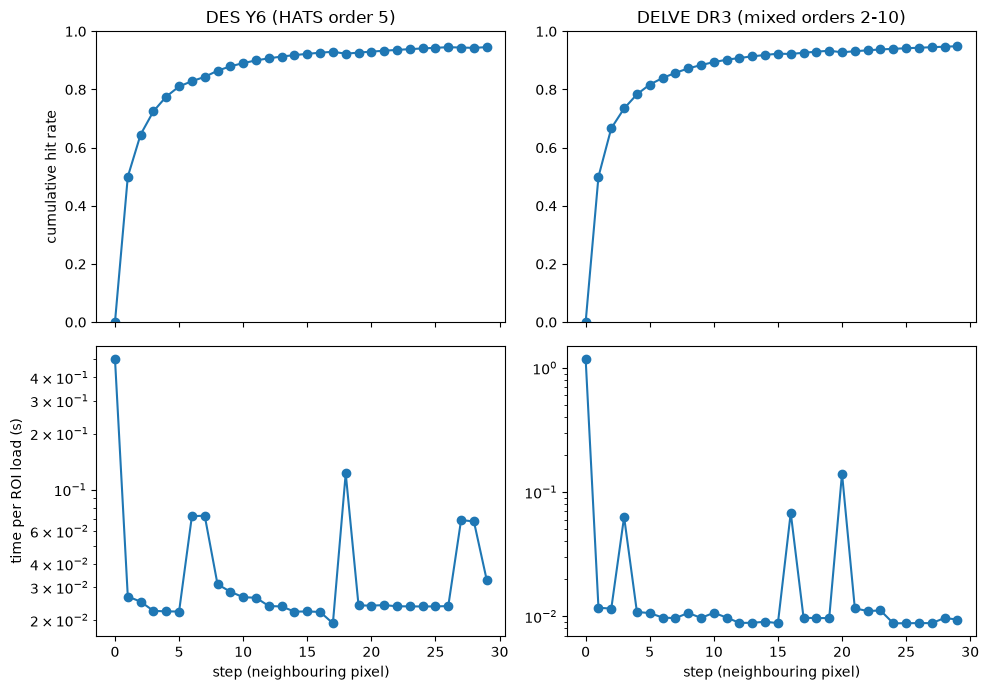

In [8]:
if HAVE_DATA:
    delve_csv = HIO / 'reader_check' / 'delve_timing.csv'
    delve = None
    if delve_csv.exists():
        delve = np.genfromtxt(delve_csv, delimiter=',', names=True)
        print('DELVE DR3 (mixed orders 2-10): %i steps, %.0f MB read, first step %.2fs, median later step %.3fs, final cum hit rate %.3f' % (
            len(delve), delve['MB'].sum(), delve['time'][0], np.median(delve['time'][1:]), delve['cum_hit_rate'][-1]))
    else:
        print('DELVE timing CSV not found; skipping that part')

    fig, ax = plt.subplots(2, 2, figsize=(10, 7), sharex='col')
    ax[0, 0].plot([r['step'] for r in des], [r['cum_hit_rate'] for r in des], 'o-')
    ax[0, 0].set_title('DES Y6 (HATS order 5)'); ax[0, 0].set_ylabel('cumulative hit rate')
    ax[1, 0].semilogy([r['step'] for r in des], [r['time'] for r in des], 'o-')
    ax[1, 0].set_ylabel('time per ROI load (s)'); ax[1, 0].set_xlabel('step (neighbouring pixel)')
    if delve is not None:
        ax[0, 1].plot(delve['step'], delve['cum_hit_rate'], 'o-')
        ax[1, 1].semilogy(delve['step'], delve['time'], 'o-')
    ax[0, 1].set_title('DELVE DR3 (mixed orders 2-10)'); ax[1, 1].set_xlabel('step (neighbouring pixel)')
    for a in ax[0]: a.set_ylim(0, 1)
    plt.tight_layout(); plt.show()
else:
    print('data not available - skipping')

The first step reads the whole working set from disk; later steps only read the few partitions at the leading edge of the walk
and are otherwise served from memory (about two orders of magnitude faster per load). DELVE DR3 has partitions at orders 2 to 10
and behaves the same way, so the mixed-order lookup does not spoil the caching.

### The cache must be larger than the working set

A 2 degree ROI touches ~10-13 partitions. If `max_tiles` is smaller than that, every request evicts partitions it needs again
immediately (LRU thrashing). Same walk, first 10 steps, `max_tiles=4` vs `64`:

 max_tiles      hits    misses   hit rate   MB read  total (s)
         4         0       108      0.000      3538        4.7
        64        95        13      0.880       424        0.8


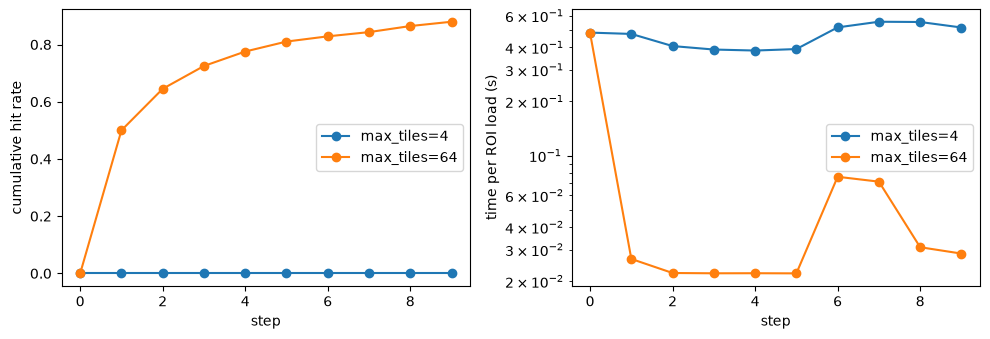

In [9]:
if HAVE_DATA:
    import logging; logging.getLogger('ugali').setLevel(logging.ERROR)
    walk10 = walk[:10]
    thr = {}
    for mt in (4, 64):
        rd = new_reader(mt)
        t0 = time.time(); recs = roi_walk(rd, walk10); tot = time.time() - t0
        thr[mt] = (recs, rd, tot)
    print('%10s %9s %9s %10s %9s %10s' % ('max_tiles', 'hits', 'misses', 'hit rate', 'MB read', 'total (s)'))
    for mt, (recs, rd, tot) in thr.items():
        print('%10i %9i %9i %10.3f %9.0f %10.1f' % (mt, rd.stats['hits'], rd.stats['misses'], rd.hit_rate, rd.stats['bytes_read'] / 1e6, tot))
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    for mt, (recs, rd, tot) in thr.items():
        ax[0].plot([r['step'] for r in recs], [r['cum_hit_rate'] for r in recs], 'o-', label='max_tiles=%i' % mt)
        ax[1].semilogy([r['step'] for r in recs], [r['time'] for r in recs], 'o-', label='max_tiles=%i' % mt)
    ax[0].set_xlabel('step'); ax[0].set_ylabel('cumulative hit rate'); ax[0].legend()
    ax[1].set_xlabel('step'); ax[1].set_ylabel('time per ROI load (s)'); ax[1].legend()
    plt.tight_layout(); plt.show()
else:
    print('data not available - skipping')

## 5. Parallel driver timing

Eight neighbouring likelihood pixels are scanned with `run_scan`:

* **old way**: FITS config, `n_jobs=1`;
* **HATS, serial**: `n_jobs=1` (one process, cache persists across pixels);
* **HATS, parallel**: `n_jobs=4` (forked workers, each with its own persistent cache; pixels handed out in contiguous NESTED chunks).

Every run uses a fresh output directory and an empty reader cache, and `force=True`. The HATS reader cache starts empty for each HATS
run; the operating-system page cache is shared by all runs, so the FITS and HATS file reads are both likely to be warm after earlier cells.
This is a time-consuming cell (a few minutes in total).

In [10]:
if HAVE_DATA:
    PIX8 = [639648, 640671, 640672, 641695, 641696, 641697, 642718, 642719]
    assert set(PIX8) <= set(pixlist.tolist())
    configs5 = [('FITS, n_jobs=1 (old)', 'fits', 1), ('HATS, n_jobs=1', 'hats', 1), ('HATS, n_jobs=4', 'hats', 4)]
    res5, cwd0 = {}, os.getcwd()
    for label, kind, nj in configs5:
        d = make_run('s5_%s_n%i' % (kind, nj), kind)
        hats_catalog._READERS.clear()          # empty in-process cache (forked workers inherit it)
        os.chdir(d)
        try:
            t0 = time.time()
            recs = run_scan(str(d / 'config.yaml'), PIX8, n_jobs=nj, force=True, stats_file=str(d / 'stats.csv'))
            wall = time.time() - t0
        finally:
            os.chdir(cwd0)
        res5[label] = dict(recs=recs, wall=wall, dir=d)
        print('--> %s: %.1fs' % (label, wall))
else:
    print('data not available - skipping')

=== Scan summary ===
pixels: 8 ok, 0 skipped, 0 failed
total time: 104.5s  (0.0766 pixels/s)
mean per-pixel runtime: 13.1s
cache: hits=0 misses=0 hit_rate=nan  read=0.0 MB
--> FITS, n_jobs=1 (old): 104.5s


=== Scan summary ===
pixels: 8 ok, 0 skipped, 0 failed
total time: 105.2s  (0.0760 pixels/s)
mean per-pixel runtime: 13.1s
cache: hits=21 misses=3 hit_rate=0.875  read=98.1 MB
--> HATS, n_jobs=1: 105.2s


=== Scan summary ===
pixels: 8 ok, 0 skipped, 0 failed
total time: 27.5s  (0.2914 pixels/s)
mean per-pixel runtime: 13.3s
cache: hits=12 misses=12 hit_rate=0.500  read=392.5 MB
--> HATS, n_jobs=4: 27.5s


configuration           wall (s)     pix/s   mean/pix    hits  misses  hit rate   MB read   fail
FITS, n_jobs=1 (old)       104.5    0.0766      13.1s       0       0       n/a         0      0
HATS, n_jobs=1             105.2    0.0760      13.1s      21       3     0.875        98      0
HATS, n_jobs=4              27.5    0.2913      13.3s      12      12     0.500       393      0

Catalog read time summed over pixels (HATS misses only): HATS, n_jobs=1: 0.1s, HATS, n_jobs=4: 0.5s
Speed-up vs old way: FITS, n_jobs=1 (old): 1.00x, HATS, n_jobs=1: 0.99x, HATS, n_jobs=4: 3.80x
max|diff| over 8 pixels, HATS, n_jobs=1 vs FITS: 0
max|diff| over 8 pixels, HATS, n_jobs=4 vs FITS: 0


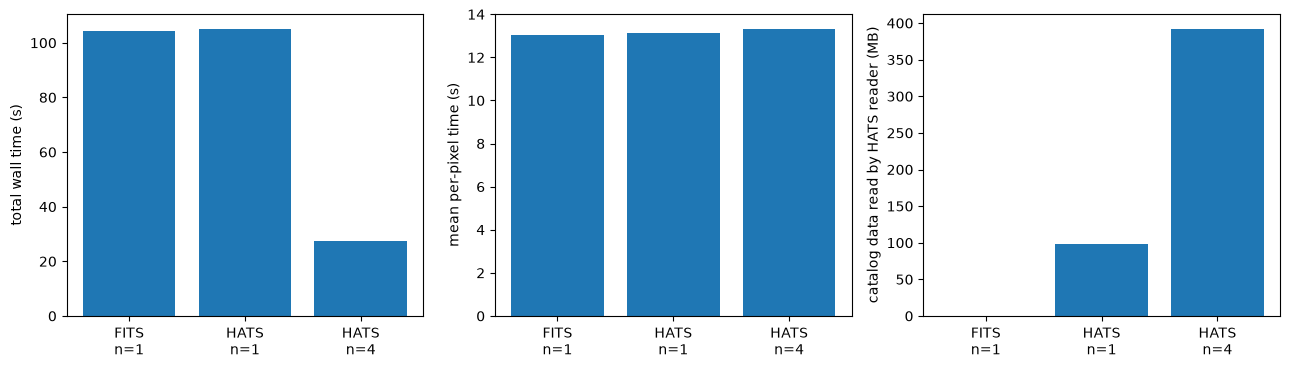

In [11]:
if HAVE_DATA:
    print('%-22s %9s %9s %10s %7s %7s %9s %9s %6s' % ('configuration', 'wall (s)', 'pix/s', 'mean/pix', 'hits', 'misses', 'hit rate', 'MB read', 'fail'))
    tab5 = {}
    for label, r in res5.items():
        ok = [x for x in r['recs'] if x['status'] == 'ok']
        h = sum(x['hits'] for x in ok); m = sum(x['misses'] for x in ok)
        t = dict(wall=r['wall'], pps=len(ok) / r['wall'], mean=np.mean([x['runtime_s'] for x in ok]), hits=h, misses=m,
                 hr=h / (h + m) if (h + m) else np.nan, mb=sum(x['bytes_read'] for x in ok) / 1e6,
                 rt=sum(x['read_time'] for x in ok), nfail=len(r['recs']) - len(ok))
        tab5[label] = t
        print('%-22s %9.1f %9.4f %9.1fs %7i %7i %9s %9.0f %6i' % (label, t['wall'], t['pps'], t['mean'], h, m,
              ('%.3f' % t['hr']) if (h + m) else 'n/a', t['mb'], t['nfail']))
    print()
    print('Catalog read time summed over pixels (HATS misses only): ' +
          ', '.join('%s: %.1fs' % (k, v['rt']) for k, v in tab5.items() if v['hits'] + v['misses']))
    base = tab5['FITS, n_jobs=1 (old)']['wall']
    print('Speed-up vs old way: ' + ', '.join('%s: %.2fx' % (k, base / v['wall']) for k, v in tab5.items()))

    # the scans must still be identical to the old-way scans
    for label in ('HATS, n_jobs=1', 'HATS, n_jobs=4'):
        worst = 0.0
        for p in PIX8:
            f = 'scan-v0/scan_%08i_cel.fits' % p
            d = max_abs_diff(res5['FITS, n_jobs=1 (old)']['dir'] / f, res5[label]['dir'] / f)
            worst = max(worst, max(d.values()))
        print('max|diff| over 8 pixels, %s vs FITS: %g' % (label, worst))

    fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
    names = list(tab5); x = np.arange(len(names)); short = ['FITS\nn=1', 'HATS\nn=1', 'HATS\nn=4']
    ax[0].bar(x, [tab5[n]['wall'] for n in names]); ax[0].set_ylabel('total wall time (s)')
    ax[1].bar(x, [tab5[n]['mean'] for n in names]); ax[1].set_ylabel('mean per-pixel time (s)')
    ax[2].bar(x, [tab5[n]['mb'] for n in names]); ax[2].set_ylabel('catalog data read by HATS reader (MB)')
    for a in ax: a.set_xticks(x); a.set_xticklabels(short)
    plt.tight_layout(); plt.show()
else:
    print('data not available - skipping')

Per-pixel compute (about 13 s of likelihood work per pixel in the current code) dominates the run, so the catalog input only changes the total
slightly. The HATS cache shows up in the misses/MB columns: with a persistent cache, the 8 pixels read each partition from disk
once instead of once per pixel (FITS reads whole per-pixel files every time). The big wall-time change comes from running pixels in
parallel. Note that with `n_jobs=4` each worker has its own cache, so the total MB read is larger than in the serial run; the
mean per-pixel time also rises a little because four processes share the machine.

## 6. Summary of findings

In [12]:
if HAVE_DATA:
    from IPython.display import Markdown, display
    import textwrap
    t = tab5
    f, s, p = t['FITS, n_jobs=1 (old)'], t['HATS, n_jobs=1'], t['HATS, n_jobs=4']
    max_hf = max(max(r[1].values()) for r in rows3)
    max_fr = max(max(r[2].values()) for r in rows3)
    max_hr = max(max(r[3].values()) for r in rows3)
    display(Markdown(textwrap.dedent('''
    * **Catalog rows**: HATS reader and FITS files (after the config selection) give identical rows for all %i test pixels (%s rows; max|diff| = %g).
    * **Scan output, same environment**: HATS vs FITS max|diff| over %i pixels = **%g** (bit-identical); `compare_fits` reports no header or column differences.
    * **Versus production reference** (numpy 1.26): FITS differs by up to %.3g and HATS by up to %.3g in this numpy 2.5 / Python 3.14 environment, the same for both inputs. This is environment drift. HATS in the numpy 1.26 environment reproduces production bit-for-bit (`hats_in_des_ugali_vs_reference.txt`).
    * **Single pixel** wall time: FITS %.1f s vs HATS %.1f s (mean of 3), i.e. catalog input is a negligible part of a one-pixel run.
    * **Cache**: a 30-pixel DES walk reads %i partitions (%.0f MB) once and reaches a hit rate of %.3f; later ROI loads take ~%.3f s vs %.2f s for the first. `max_tiles` below the ROI working set (4 vs 64) drops the hit rate to %.2f (vs %.2f) over 10 steps.
    * **8 neighbouring pixels**: FITS serial %.0f s; HATS serial %.0f s (hit rate %.2f, %.0f MB read); HATS with 4 workers %.0f s (%.1fx faster than the old way, %.4f pix/s vs %.4f).
    * Per-pixel compute dominates, so the parallel driver is where wall-time is saved; the HATS cache reduces repeated catalog reads (disk and memory traffic) rather than overall runtime.
    ''') % (len(cat_rows), ', '.join(str(r[2]) for r in cat_rows), max(r[5] for r in cat_rows),
           len(PIX3), max_hf, max_fr, max_hr,
           np.mean([t3[('fits', q)] for q in PIX3]), np.mean([t3[('hats', q)] for q in PIX3]),
           r64.stats['misses'], r64.stats['bytes_read'] / 1e6, r64.hit_rate, np.median([r['time'] for r in des[1:]]), des[0]['time'],
           thr[4][1].hit_rate, thr[64][1].hit_rate,
           f['wall'], s['wall'], s['hr'], s['mb'], p['wall'], f['wall'] / p['wall'], p['pps'], f['pps'])))
else:
    print('data not available - skipping')


* **Catalog rows**: HATS reader and FITS files (after the config selection) give identical rows for all 3 test pixels (77218, 73322, 82113 rows; max|diff| = 0).
* **Scan output, same environment**: HATS vs FITS max|diff| over 3 pixels = **0** (bit-identical); `compare_fits` reports no header or column differences.
* **Versus production reference** (numpy 1.26): FITS differs by up to 0.0555 and HATS by up to 0.0555 in this numpy 2.5 / Python 3.14 environment, the same for both inputs. This is environment drift. HATS in the numpy 1.26 environment reproduces production bit-for-bit (`hats_in_des_ugali_vs_reference.txt`).
* **Single pixel** wall time: FITS 13.6 s vs HATS 13.9 s (mean of 3), i.e. catalog input is a negligible part of a one-pixel run.
* **Cache**: a 30-pixel DES walk reads 17 partitions (554 MB) once and reaches a hit rate of 0.946; later ROI loads take ~0.024 s vs 0.50 s for the first. `max_tiles` below the ROI working set (4 vs 64) drops the hit rate to 0.00 (vs 0.88) over 10 steps.
* **8 neighbouring pixels**: FITS serial 104 s; HATS serial 105 s (hit rate 0.88, 98 MB read); HATS with 4 workers 27 s (3.8x faster than the old way, 0.2913 pix/s vs 0.0766).
* Per-pixel compute dominates, so the parallel driver is where wall-time is saved; the HATS cache reduces repeated catalog reads (disk and memory traffic) rather than overall runtime.


## How to run

Add a `hats:` block to the `catalog:` section of the ugali configuration instead of `dirname`/`basename`
(everything else, including `selection` and the field names, is unchanged):

```yaml
catalog:
  hats:
    path: /astro/store/shire/hats/catalogs/des/des_y6_gold/des_y6_gold
    max_tiles: 64      # LRU cache size in partitions; keep it above the ~10-13 partitions of one 2 deg ROI
  lon_field: RA
  lat_field: DEC
  objid_field: COADD_OBJECT_ID
  # ... mag fields, selection etc. as before
```

Single pixel (unchanged interface):

```
python ugali/analysis/scan.py config.yaml scan_00639648_cel.fits --hpx 256 639648
```

Many pixels on one machine, with persistent per-worker caches and a per-pixel statistics file:

```
python ugali/analysis/scan_parallel.py config.yaml --pixels 639648 640671 640672 641695 -n 4 --stats-file stats.csv
python ugali/analysis/scan_parallel.py config.yaml --hpxlist pixels.txt -n 16 --max-tiles 64
```